In [1]:
!pip install pymoo matplotlib -q

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [3]:
class PortfolioProblem(ElementwiseProblem):

    def __init__(self):
        super().__init__(
            n_var=2,
            n_obj=2,
            xl=np.array([0.0, 0.0]),
            xu=np.array([100.0, 100.0])
        )

    def _evaluate(self, x, out, *args, **kwargs):

        rf = x[0]
        acoes = x[1]

        # Maximizar retorno
        f1_retorno_negativo = -(
            (rf * 0.08) + (acoes * 0.18)
        )

        # Minimizar risco
        f2_risco = (
            (rf * 0.02) + (acoes * 0.25)
        )

        out["F"] = [f1_retorno_negativo, f2_risco]


print("Problema de investimentos criado com sucesso!")

Problema de investimentos criado com sucesso!


In [4]:
res4 = minimize(
    PortfolioProblem(),
    NSGA2(pop_size=40),
    termination=('n_gen', 50),
    seed=4
)

print("Otimização concluída com sucesso!")

Otimização concluída com sucesso!


In [5]:
print("RESULTADOS DO EXERCÍCIO 4")
print("=" * 50)

for i in range(len(res4.F)):

    rf = res4.X[i, 0]
    acoes = res4.X[i, 1]

    retorno = -res4.F[i, 0]
    risco = res4.F[i, 1]

    print(f"Solução {i+1}")
    print(f"Renda fixa: {rf:.2f}%")
    print(f"Ações: {acoes:.2f}%")
    print(f"Retorno esperado: {retorno:.2f}")
    print(f"Risco: {risco:.2f}")
    print("-" * 30)

RESULTADOS DO EXERCÍCIO 4
Solução 1
Renda fixa: 37.94%
Ações: 0.07%
Retorno esperado: 3.05
Risco: 0.78
------------------------------
Solução 2
Renda fixa: 100.00%
Ações: 100.00%
Retorno esperado: 26.00
Risco: 27.00
------------------------------
Solução 3
Renda fixa: 100.00%
Ações: 72.19%
Retorno esperado: 20.99
Risco: 20.05
------------------------------
Solução 4
Renda fixa: 59.46%
Ações: 0.00%
Retorno esperado: 4.76
Risco: 1.19
------------------------------
Solução 5
Renda fixa: 100.00%
Ações: 77.32%
Retorno esperado: 21.92
Risco: 21.33
------------------------------
Solução 6
Renda fixa: 99.98%
Ações: 19.77%
Retorno esperado: 11.56
Risco: 6.94
------------------------------
Solução 7
Renda fixa: 99.99%
Ações: 42.10%
Retorno esperado: 15.58
Risco: 12.52
------------------------------
Solução 8
Renda fixa: 99.58%
Ações: 29.27%
Retorno esperado: 13.24
Risco: 9.31
------------------------------
Solução 9
Renda fixa: 99.97%
Ações: 88.03%
Retorno esperado: 23.84
Risco: 24.01
----------

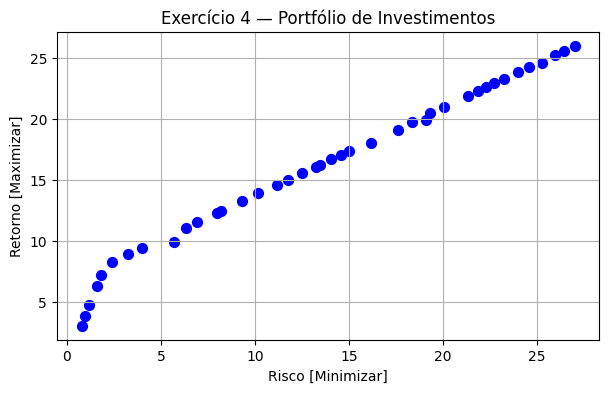

In [6]:
plt.figure(figsize=(7, 4))

plt.scatter(
    res4.F[:, 1],
    -res4.F[:, 0],
    color='blue',
    s=50
)

plt.title("Exercício 4 — Portfólio de Investimentos")
plt.xlabel("Risco [Minimizar]")
plt.ylabel("Retorno [Maximizar]")

plt.grid(True)
plt.show()